# 04 — Visual check
Hiển thị tối đa 10 **ảnh khác nhau** cho mỗi class của từng dataset. Chọn mẫu cố định (`seed=42`) để dễ tái lập; khung đỏ là class đang xem, khung xám là class khác. Chỉ vẽ box hợp lệ sau kiểm tra; lỗi annotation được liệt kê ở notebook 02. Ảnh chỉ hiển thị trong notebook, không lưu ra đĩa.

In [1]:
import json
import random
from pathlib import Path
from matplotlib.patches import Rectangle
notebook_path = next((p / 'scripts' / '01_inventory.ipynb' for p in (Path.cwd(), *Path.cwd().parents) if (p / 'scripts' / '01_inventory.ipynb').is_file()), None)
if notebook_path is None:
    raise FileNotFoundError('01_inventory.ipynb not found: run inside the project.')
exec(compile(''.join(json.loads(notebook_path.read_text(encoding='utf-8'))['cells'][1]['source']), str(notebook_path), 'exec'))


/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


## DeepPCB — open: 10 / 1344 ảnh có box hợp lệ

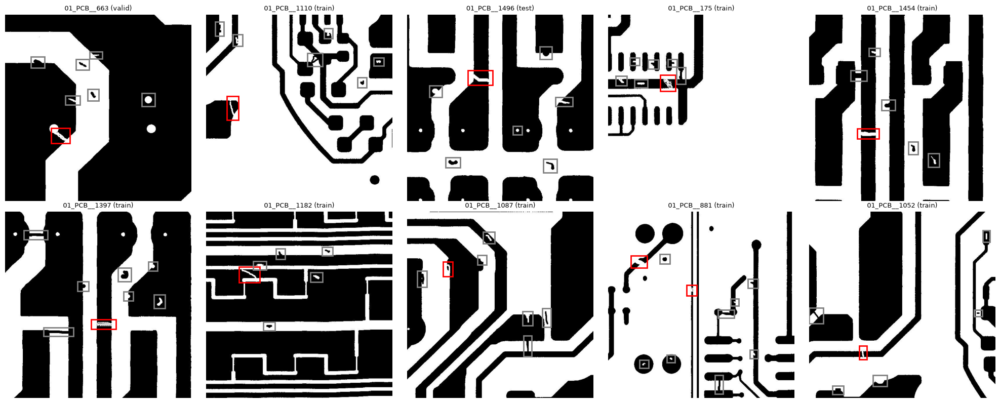

## DeepPCB — short: 10 / 1101 ảnh có box hợp lệ

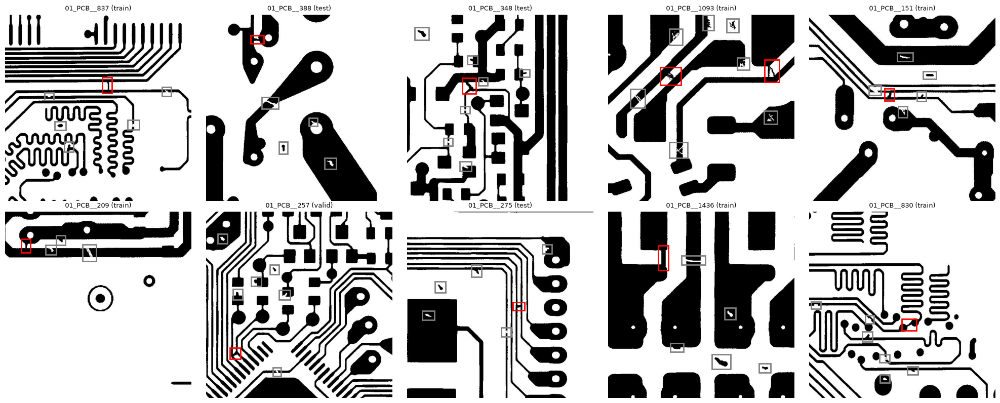

## DeepPCB — mousebite: 10 / 1269 ảnh có box hợp lệ

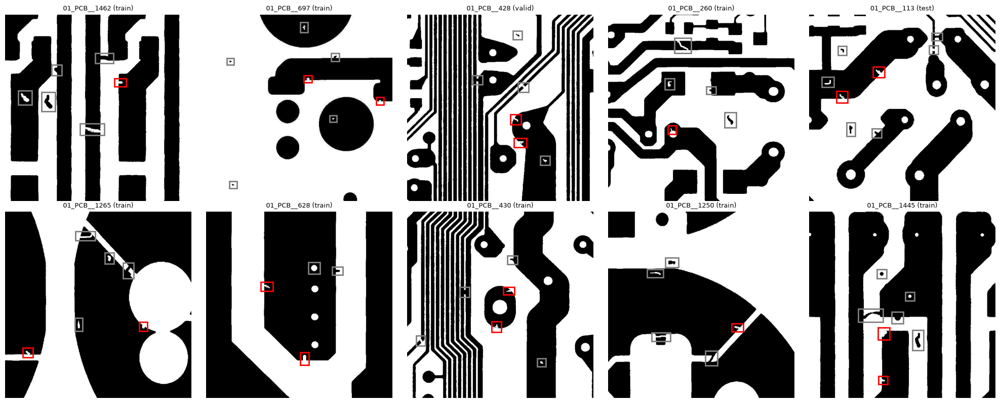

## DeepPCB — spur: 10 / 1184 ảnh có box hợp lệ

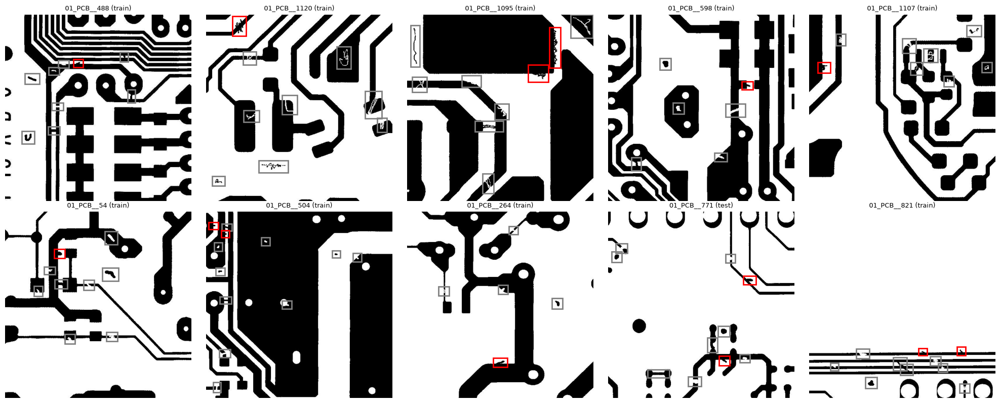

## DeepPCB — copper: 10 / 1241 ảnh có box hợp lệ

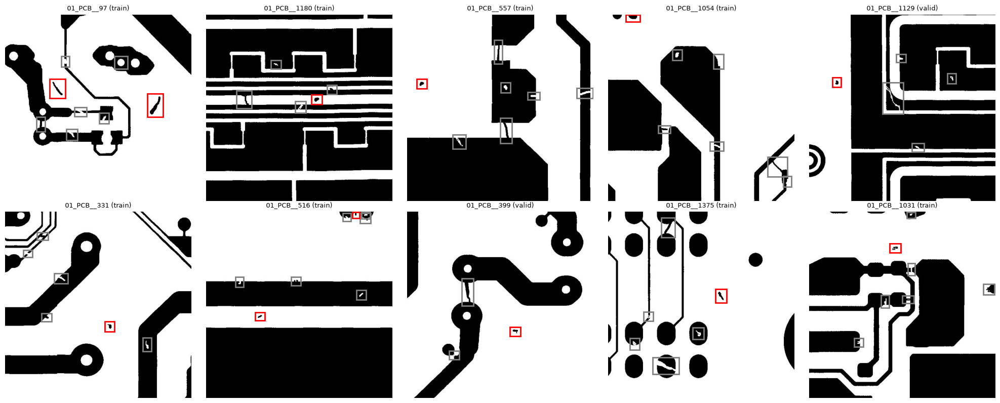

## DeepPCB — pin-hole: 10 / 1315 ảnh có box hợp lệ

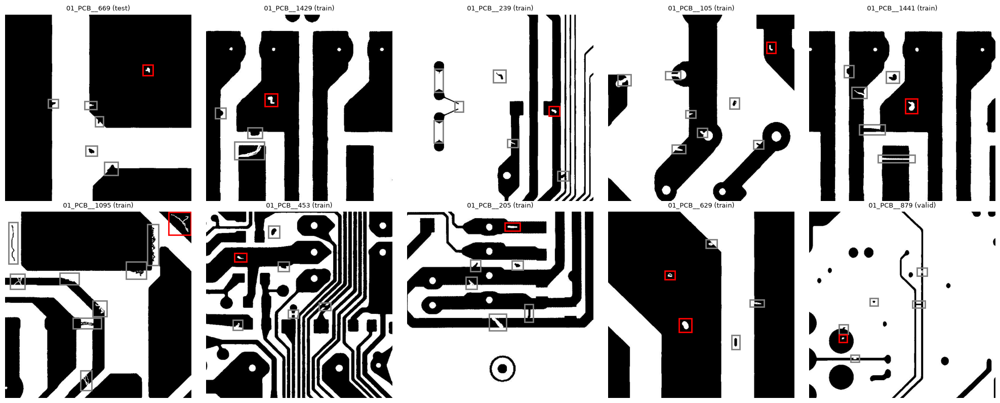

## PKU — Missing_hole: 10 / 582 ảnh có box hợp lệ

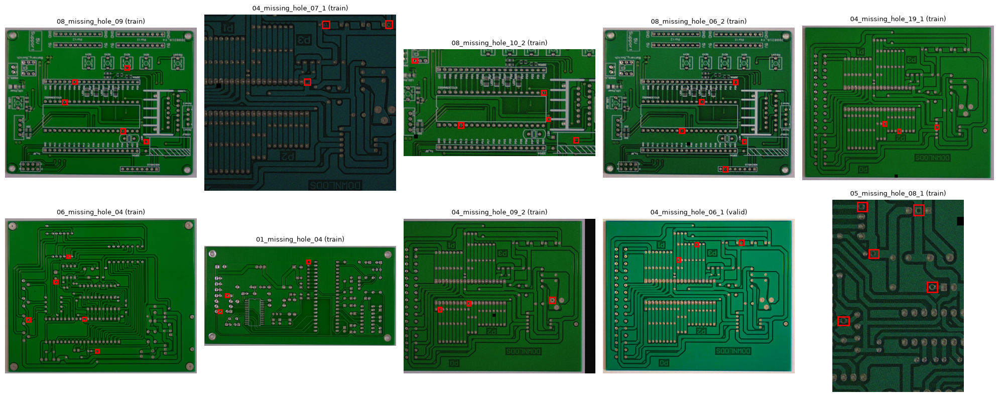

## PKU — Mouse_bite: 10 / 582 ảnh có box hợp lệ

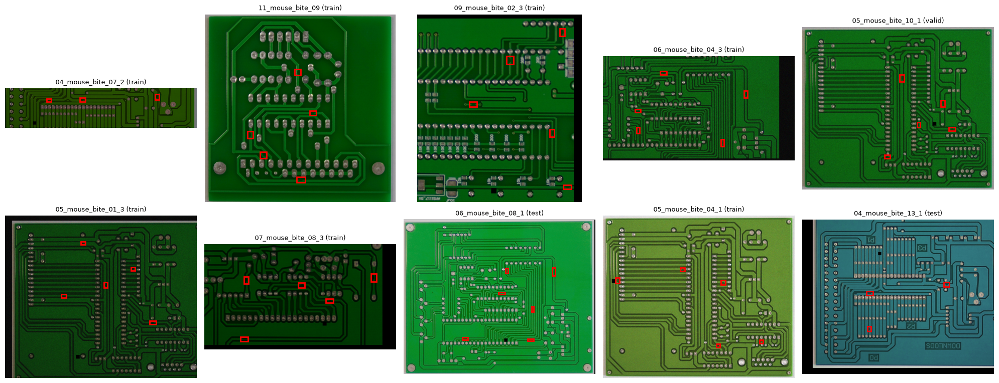

## PKU — Open_circuit: 10 / 586 ảnh có box hợp lệ

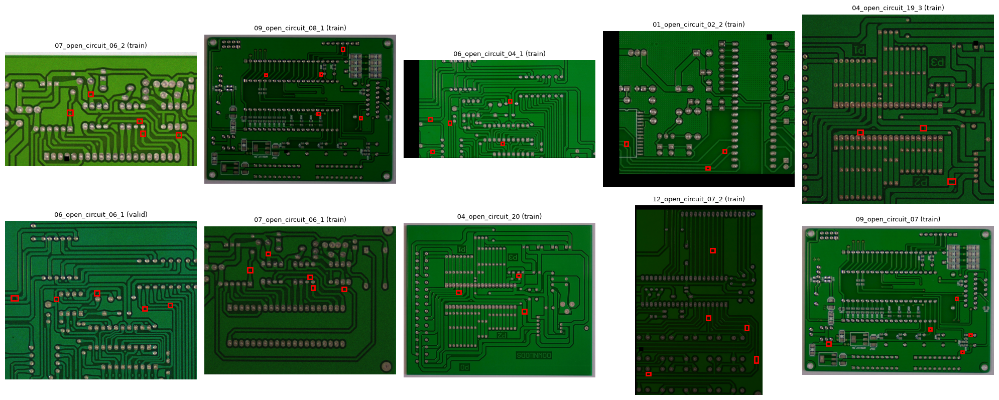

## PKU — Short: 10 / 586 ảnh có box hợp lệ

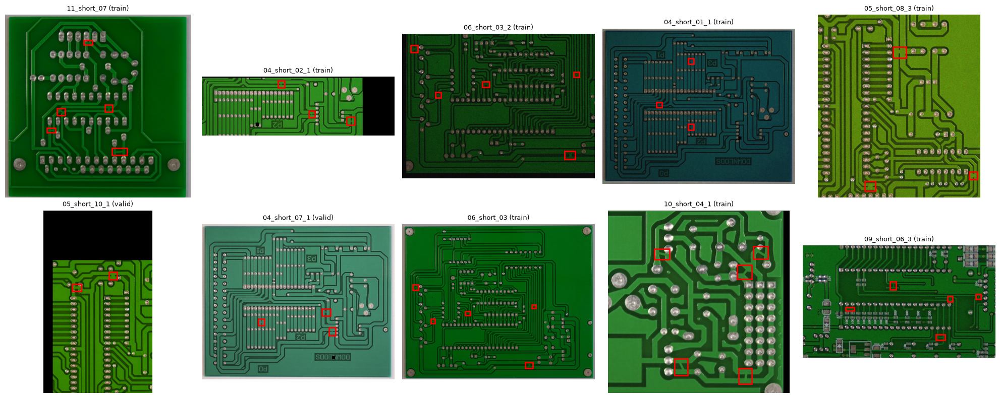

## PKU — Spur: 10 / 582 ảnh có box hợp lệ

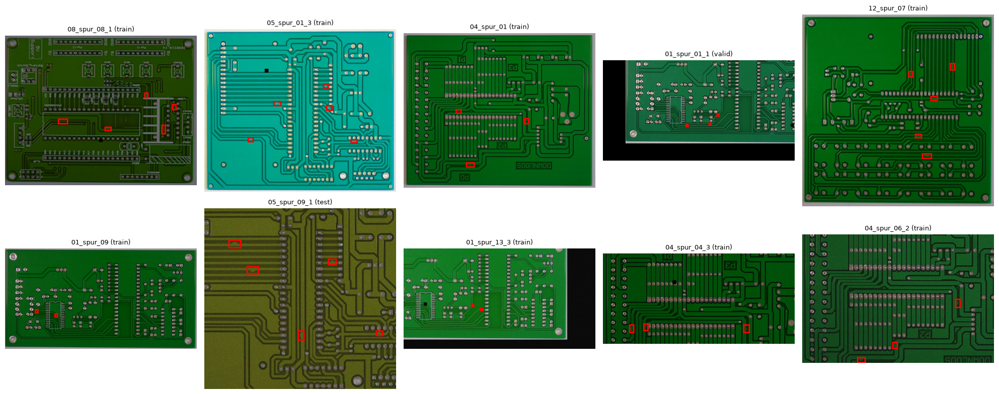

## PKU — Spurious_copper: 10 / 586 ảnh có box hợp lệ

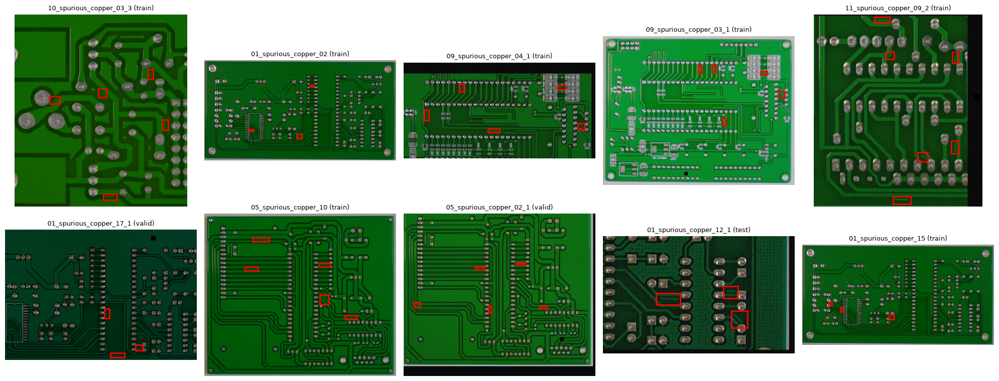

In [2]:
rng = random.Random(42)
for name, result in all_audits().items():
    df = result['boxes']
    for class_id, class_name in enumerate(result['classes']):
        candidates = sorted(result['images_by_class'][class_id])
        selected = rng.sample(candidates, min(10, len(candidates)))
        display(Markdown(f'## {name} — {class_name}: {len(selected)} / {len(candidates)} ảnh có box hợp lệ'))
        if not selected:
            display(Markdown('Không có ảnh chứa box hợp lệ cho class này.'))
            continue
        fig, axes = plt.subplots(2, 5, figsize=(20, 8))
        for ax, image in zip(axes.flat, selected):
            with Image.open(image) as im:
                ax.imshow(im.convert('RGB'))
            for box in df[df['image'] == str(image.relative_to(ROOT))].itertuples():
                color = 'red' if box.class_id == class_id else 'gray'
                ax.add_patch(Rectangle((box.x1, box.y1), box.width_px, box.height_px, fill=False, edgecolor=color, linewidth=2))
            ax.set_title(f'{image.stem} ({image.parent.parent.name})', fontsize=9)
            ax.axis('off')
        for ax in list(axes.flat)[len(selected):]:
            ax.axis('off')
        plt.tight_layout()
        plt.show()
